# 01 · EDA and training
Exploration of the Kaggle credit-card fraud dataset (ULB, European cardholders, September 2013) and the training pipeline used by Tasks 9-10. All model code lives in `src/`; this notebook inspects the data and re-uses the saved artifacts.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config as C
df = pd.read_csv(C.CLEAN_CSV)
print(df.shape); df.head()

(283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
summary = json.load(open(C.PROCESSED_DIR / 'data_summary.json'))
print('duplicates removed:', summary['duplicates_removed'], '| missing values:', int(df.isna().sum().sum()))
print('fraud rows:', int(df[C.TARGET].sum()), '| fraud rate:', round(df[C.TARGET].mean(), 5), '| time span (h):', summary['time_span_hours'])

duplicates removed: 1081 | missing values: 0
fraud rows: 473 | fraud rate: 0.00167 | time span (h): 48.0


## Class imbalance, amount and time of day

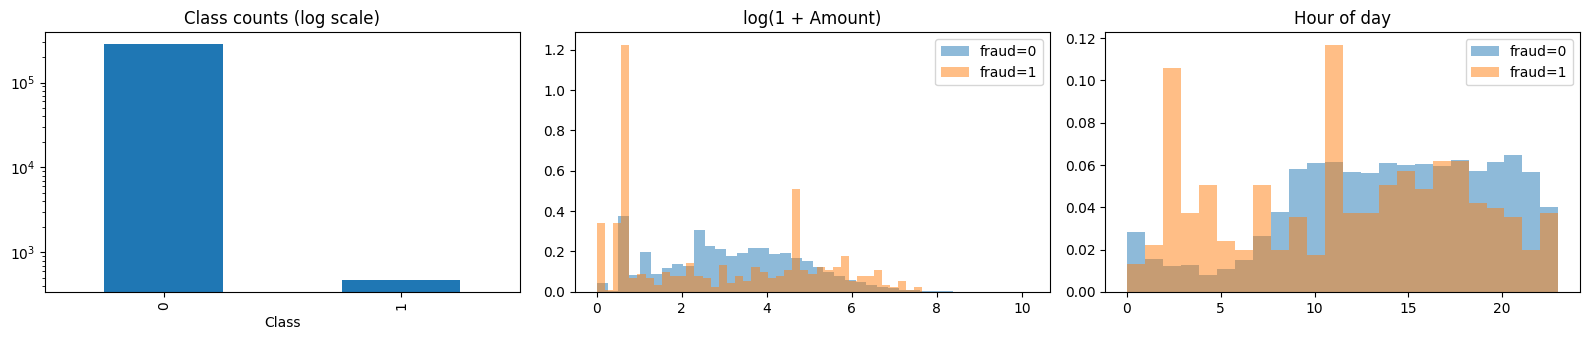

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.5))
df[C.TARGET].value_counts().plot.bar(ax=axs[0], logy=True, title='Class counts (log scale)')
for lab, d in df.groupby(C.TARGET):
    axs[1].hist(np.log1p(d.Amount), bins=40, alpha=.5, density=True, label=f'fraud={lab}')
    axs[2].hist((d[C.TIME_COL] // 3600) % 24, bins=24, alpha=.5, density=True, label=f'fraud={lab}')
axs[1].set_title('log(1 + Amount)'); axs[2].set_title('Hour of day'); axs[1].legend(); axs[2].legend()
plt.tight_layout(); plt.show()

## Which PCA components separate fraud from legitimate transactions?

{'V17': 7.68, 'V14': 7.19, 'V12': 6.15, 'V10': 5.07, 'V16': 4.59, 'V3': 4.47, 'V7': 4.22, 'V11': 3.65}


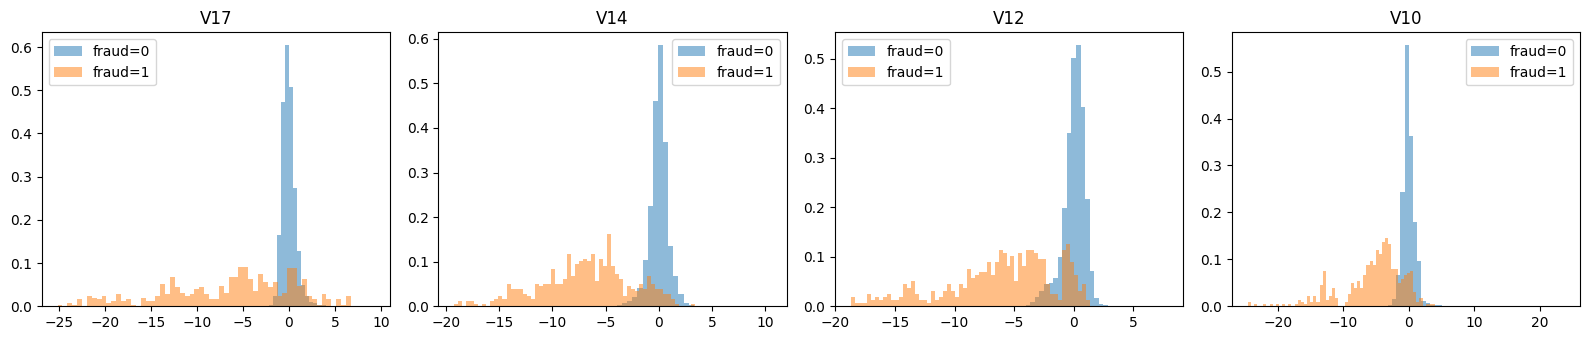

In [4]:
sep = (df.groupby(C.TARGET)[C.PCA_INPUTS].mean().diff().iloc[-1] / df[C.PCA_INPUTS].std()).abs().sort_values(ascending=False)
print(sep.head(8).round(2).to_dict())
fig, axs = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axs, sep.index[:4]):
    for lab, d in df.groupby(C.TARGET): ax.hist(d[col], bins=60, alpha=.5, density=True, label=f'fraud={lab}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

Several components (V14, V12, V10, V17, ...) shift strongly for fraud, so unlike a balanced synthetic dataset there is a real, learnable signal. The challenge here is the extreme imbalance (≈0.17% fraud).

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
X = df[C.PCA_INPUTS + ['Amount']]
cv = StratifiedKFold(5, shuffle=True, random_state=C.SEED)
for metric in ['roc_auc', 'average_precision']:
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X, df[C.TARGET], cv=cv, scoring=metric)
    print(f'5-fold logistic regression {metric}:', s.round(3), 'mean', s.mean().round(3))

5-fold logistic regression roc_auc: [0.969 0.973 0.978 0.976 0.977] mean 0.975


5-fold logistic regression average_precision: [0.773 0.738 0.714 0.741 0.739] mean 0.741


## Trained models (from `python -m src.train`)

In [6]:
meta = json.load(open(C.METADATA_PATH)); m = json.load(open(C.REPORTS_DIR / 'metrics.json'))
print({k: meta[k] for k in ['dataset_rows', 'split_sizes', 'threshold', 'threshold_f1_unconstrained', 'threshold_cost_optimal', 'epochs_run', 'trained_at']})
pd.DataFrame({'DNN': m['dnn'], 'LR': m['lr']}).drop('confusion_matrix').round(4)

{'dataset_rows': 283726, 'split_sizes': {'train': 198608, 'val': 42559, 'test': 42559}, 'threshold': 0.4, 'threshold_f1_unconstrained': 0.4, 'threshold_cost_optimal': 0.04, 'epochs_run': 38, 'trained_at': '2026-10-25T17:19:37+00:00'}


,DNN,LR
threshold,0.4,0.5
roc_auc,0.950815,0.969287
pr_auc,0.710513,0.724998
f1,0.8,0.752
precision,0.811594,0.87037
recall,0.788732,0.661972
accuracy,0.999342,0.999272
flag_rate,0.001621,0.001269


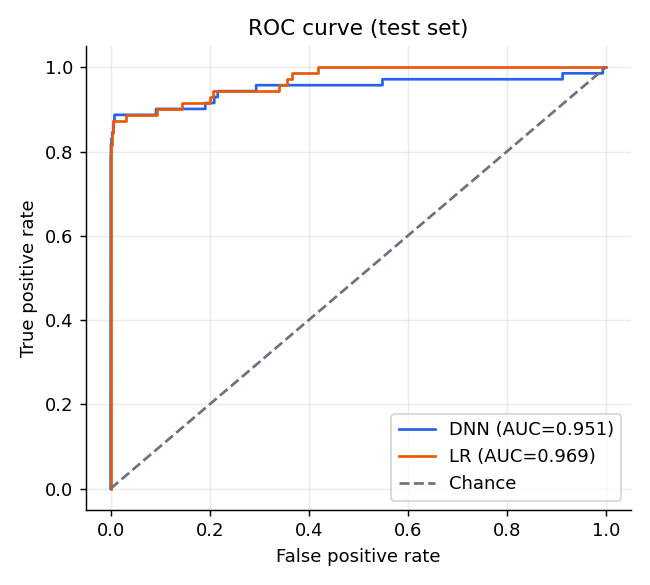

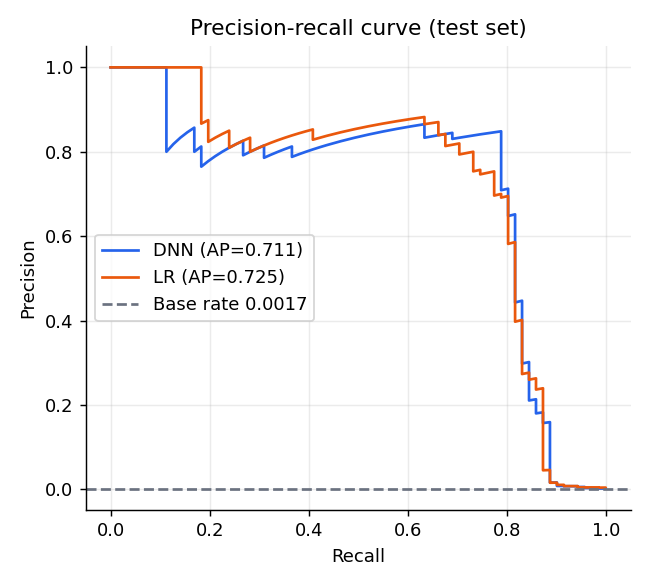

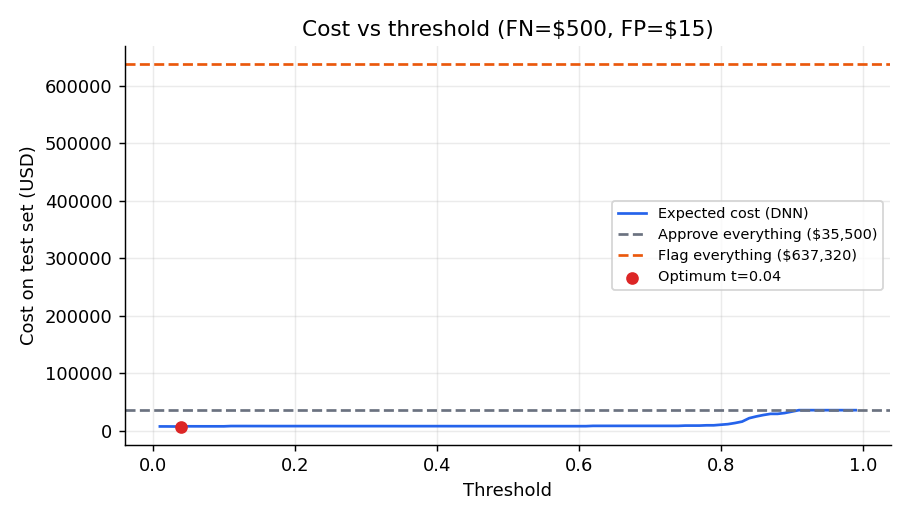

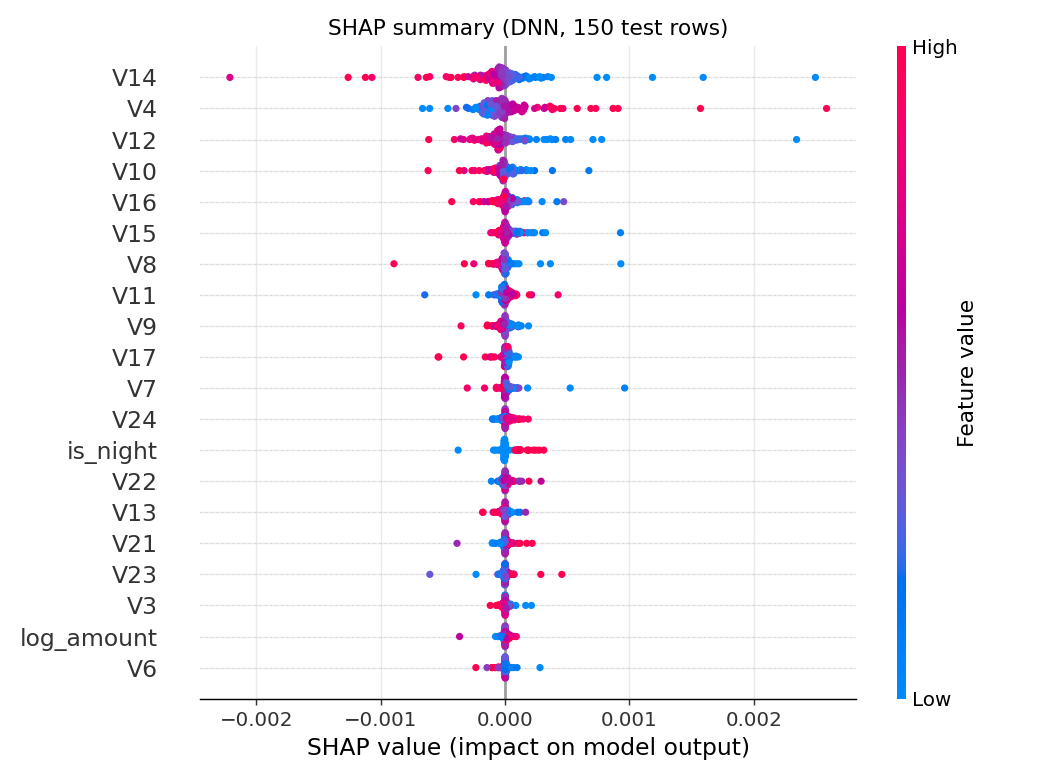

In [7]:
from IPython.display import Image, display
for f in ['roc_curve', 'pr_curve', 'cost_threshold_analysis', 'shap_summary']: display(Image(str(C.FIGURES_DIR / f'{f}.png')))

**Conclusion:** both models rank fraud well (test ROC-AUC ≈0.95-0.97, PR-AUC ≈0.71-0.72 against a 0.17% base rate). Because positives are so rare, PR-AUC, precision and recall, not accuracy, are the meaningful metrics, and the operating threshold is chosen on the validation split.